In [1]:
import os
import numpy as np
from scipy.ndimage import gaussian_filter
import matplotlib.pyplot as plt
import os
import sys
module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from GLOBAL.ground_truths import *

def load_data(directory, channel='particle'):

    prefix = 'chunk_pf_' if channel == 'particle' else 'chunk_kf_'

    chunk_files = [file for file in os.listdir(directory) if file.startswith(prefix) and file.endswith('.npz')]

    n_chunks_alpha = 0
    n_chunks_k = 0
    for file in chunk_files:
        # Load the file using np.load
        data = np.load(os.path.join(directory, file))

        alpha_idx = file.split('_')[2]
        k_idx = file.split('_')[3].split('.')[0]

        if int(alpha_idx) >= n_chunks_alpha:
            n_chunks_alpha = int(alpha_idx) + 1

        if int(k_idx) >= n_chunks_k:
            n_chunks_k = int(k_idx) + 1

    resolution_per_chunk = data['logl'].shape[0]

    LOGL = np.full((n_chunks_alpha * resolution_per_chunk, n_chunks_k * resolution_per_chunk), np.nan)

    alpha_min = +np.inf
    alpha_max = -np.inf
    k_min = +np.inf
    k_max = -np.inf

    for file in chunk_files:
        # Load the file using np.load
        data = np.load(os.path.join(directory, file))

        alpha_idx = file.split('_')[2]
        k_idx = file.split('_')[3].split('.')[0]

        alpha_max = max(alpha_max, data['alpha_grid'].max())
        alpha_min = min(alpha_min, data['alpha_grid'].min())
        k_max = max(k_max, data['k_grid'].max())
        k_min = min(k_min, data['k_grid'].min())

        LOGL[int(alpha_idx) * resolution_per_chunk:(int(alpha_idx) + 1) * resolution_per_chunk,
            int(k_idx) * resolution_per_chunk:(int(k_idx) + 1) * resolution_per_chunk] = data['logl'].T

    LOGL = LOGL.T
    extent = [alpha_min, alpha_max, k_min, k_max]
    return LOGL, extent

In [2]:
def stitch_data(directory, delete_chunks=False):
    # check if chunk files are present and if results.npz is aleady present. otherwise, load the data and save it. Warn if both types are missing.
    chunk_files = [file for file in os.listdir(directory) if file.startswith('chunk_') and file.endswith('.npz')]
    if len(chunk_files) == 0:
        if 'results.npz' in os.listdir(directory):
            return
        else:
            raise FileNotFoundError('No chunk files found and no results.npz found. Please run the estimation first.')

    LOGL_kf, extent = load_data(directory, 'kalman')
    LOGL_pf, _ = load_data(directory, 'particle')
    np.savez(os.path.join(directory, 'results.npz'), LOGL_kf=LOGL_kf, LOGL_pf=LOGL_pf, extent=extent)
    # delete chunk files
    if delete_chunks:
        for file in chunk_files:
            os.remove(os.path.join(directory, file))

In [20]:
def plot_dataset(directory, dpi=90, save_filename=None):
    result_file = np.load(os.path.join(directory, 'results.npz'))
    extent = result_file['extent']
    LOGL_kf = result_file['LOGL_kf']
    LOGL_pf = result_file['LOGL_pf']

    P_kf = np.exp(LOGL_kf - np.nanmax(LOGL_kf))
    P_kf /= np.nansum(P_kf)
    P_kf = gaussian_filter(P_kf, 3)
    P_pf = np.exp(LOGL_pf - np.nanmax(LOGL_pf))
    P_pf /= np.nansum(P_pf)
    P_pf = gaussian_filter(P_pf, 3)

    K_idx, ALPHA_idx = np.unravel_index(np.nanargmax(P_pf), P_pf.shape)
    ALPHA_MLE_pf = extent[0] + ALPHA_idx * (extent[1] - extent[0]) / LOGL_pf.shape[0]
    K_MLE_pf = extent[2] + K_idx * (extent[3] - extent[2]) / LOGL_pf.shape[1]

    K_idx, ALPHA_idx = np.unravel_index(np.nanargmax(P_kf), P_kf.shape)
    ALPHA_MLE_kf = extent[0] + ALPHA_idx * (extent[1] - extent[0]) / LOGL_kf.shape[0]
    K_MLE_kf = extent[2] + K_idx * (extent[3] - extent[2]) / LOGL_kf.shape[1]

    ground_truth_visible = ALPHA > extent[0] and ALPHA < extent[1] and K > extent[2] and K < extent[3]

    plt.figure(figsize=(7, 7), dpi=dpi)
    plt.subplot(2, 2, 1)
    plt.imshow(LOGL_kf, extent=extent, origin='lower', aspect='auto')
    plt.xlabel(r"$\alpha_1$")
    plt.ylabel(r"$\alpha_2$")
    if ground_truth_visible:
        plt.plot(ALPHA, K, 'or', linewidth=2)
    plt.axhline(K_MLE_kf, color='w', linestyle='--', lw=0.5)
    plt.axvline(ALPHA_MLE_kf, color='w', linestyle='--', lw=0.5)
    #plt.title('Kalman Filter')
    plt.subplot(2, 2, 3)
    plt.xlabel(r"$\alpha_1$")
    plt.ylabel(r"$\alpha_2$")
    plt.imshow(LOGL_pf, extent=extent, origin='lower', aspect='auto')
    if ground_truth_visible:
        plt.plot(ALPHA, K, 'or', linewidth=2)
    plt.axhline(K_MLE_pf, color='w', linestyle='--', lw=0.5)
    plt.axvline(ALPHA_MLE_pf, color='w', linestyle='--', lw=0.5)
    #plt.title('Particle Filter')
    plt.subplot(2, 2, 2)
    plt.xlabel(r"$\alpha_1$")
    #plt.ylabel(r"$\alpha_2$")
    plt.imshow(P_kf, extent=extent, origin='lower', aspect='auto')
    if ground_truth_visible:
        plt.plot(ALPHA, K, 'or', linewidth=2)
    plt.axhline(K_MLE_kf, color='w', linestyle='--', lw=0.5)
    plt.axvline(ALPHA_MLE_kf, color='w', linestyle='--', lw=0.5)
    plt.subplot(2, 2, 4)
    plt.xlabel(r"$\alpha_1$")
    #plt.ylabel(r"$\alpha_2$")
    plt.imshow(P_pf, extent=extent, origin='lower', aspect='auto')
    if ground_truth_visible:
        plt.plot(ALPHA, K, 'or', linewidth=2)
    plt.axhline(K_MLE_pf, color='w', linestyle='--', lw=0.5)
    plt.axvline(ALPHA_MLE_pf, color='w', linestyle='--', lw=0.5)
    if save_filename is not None:
        plt.savefig(save_filename, dpi=dpi, bbox_inches='tight')
    plt.show()



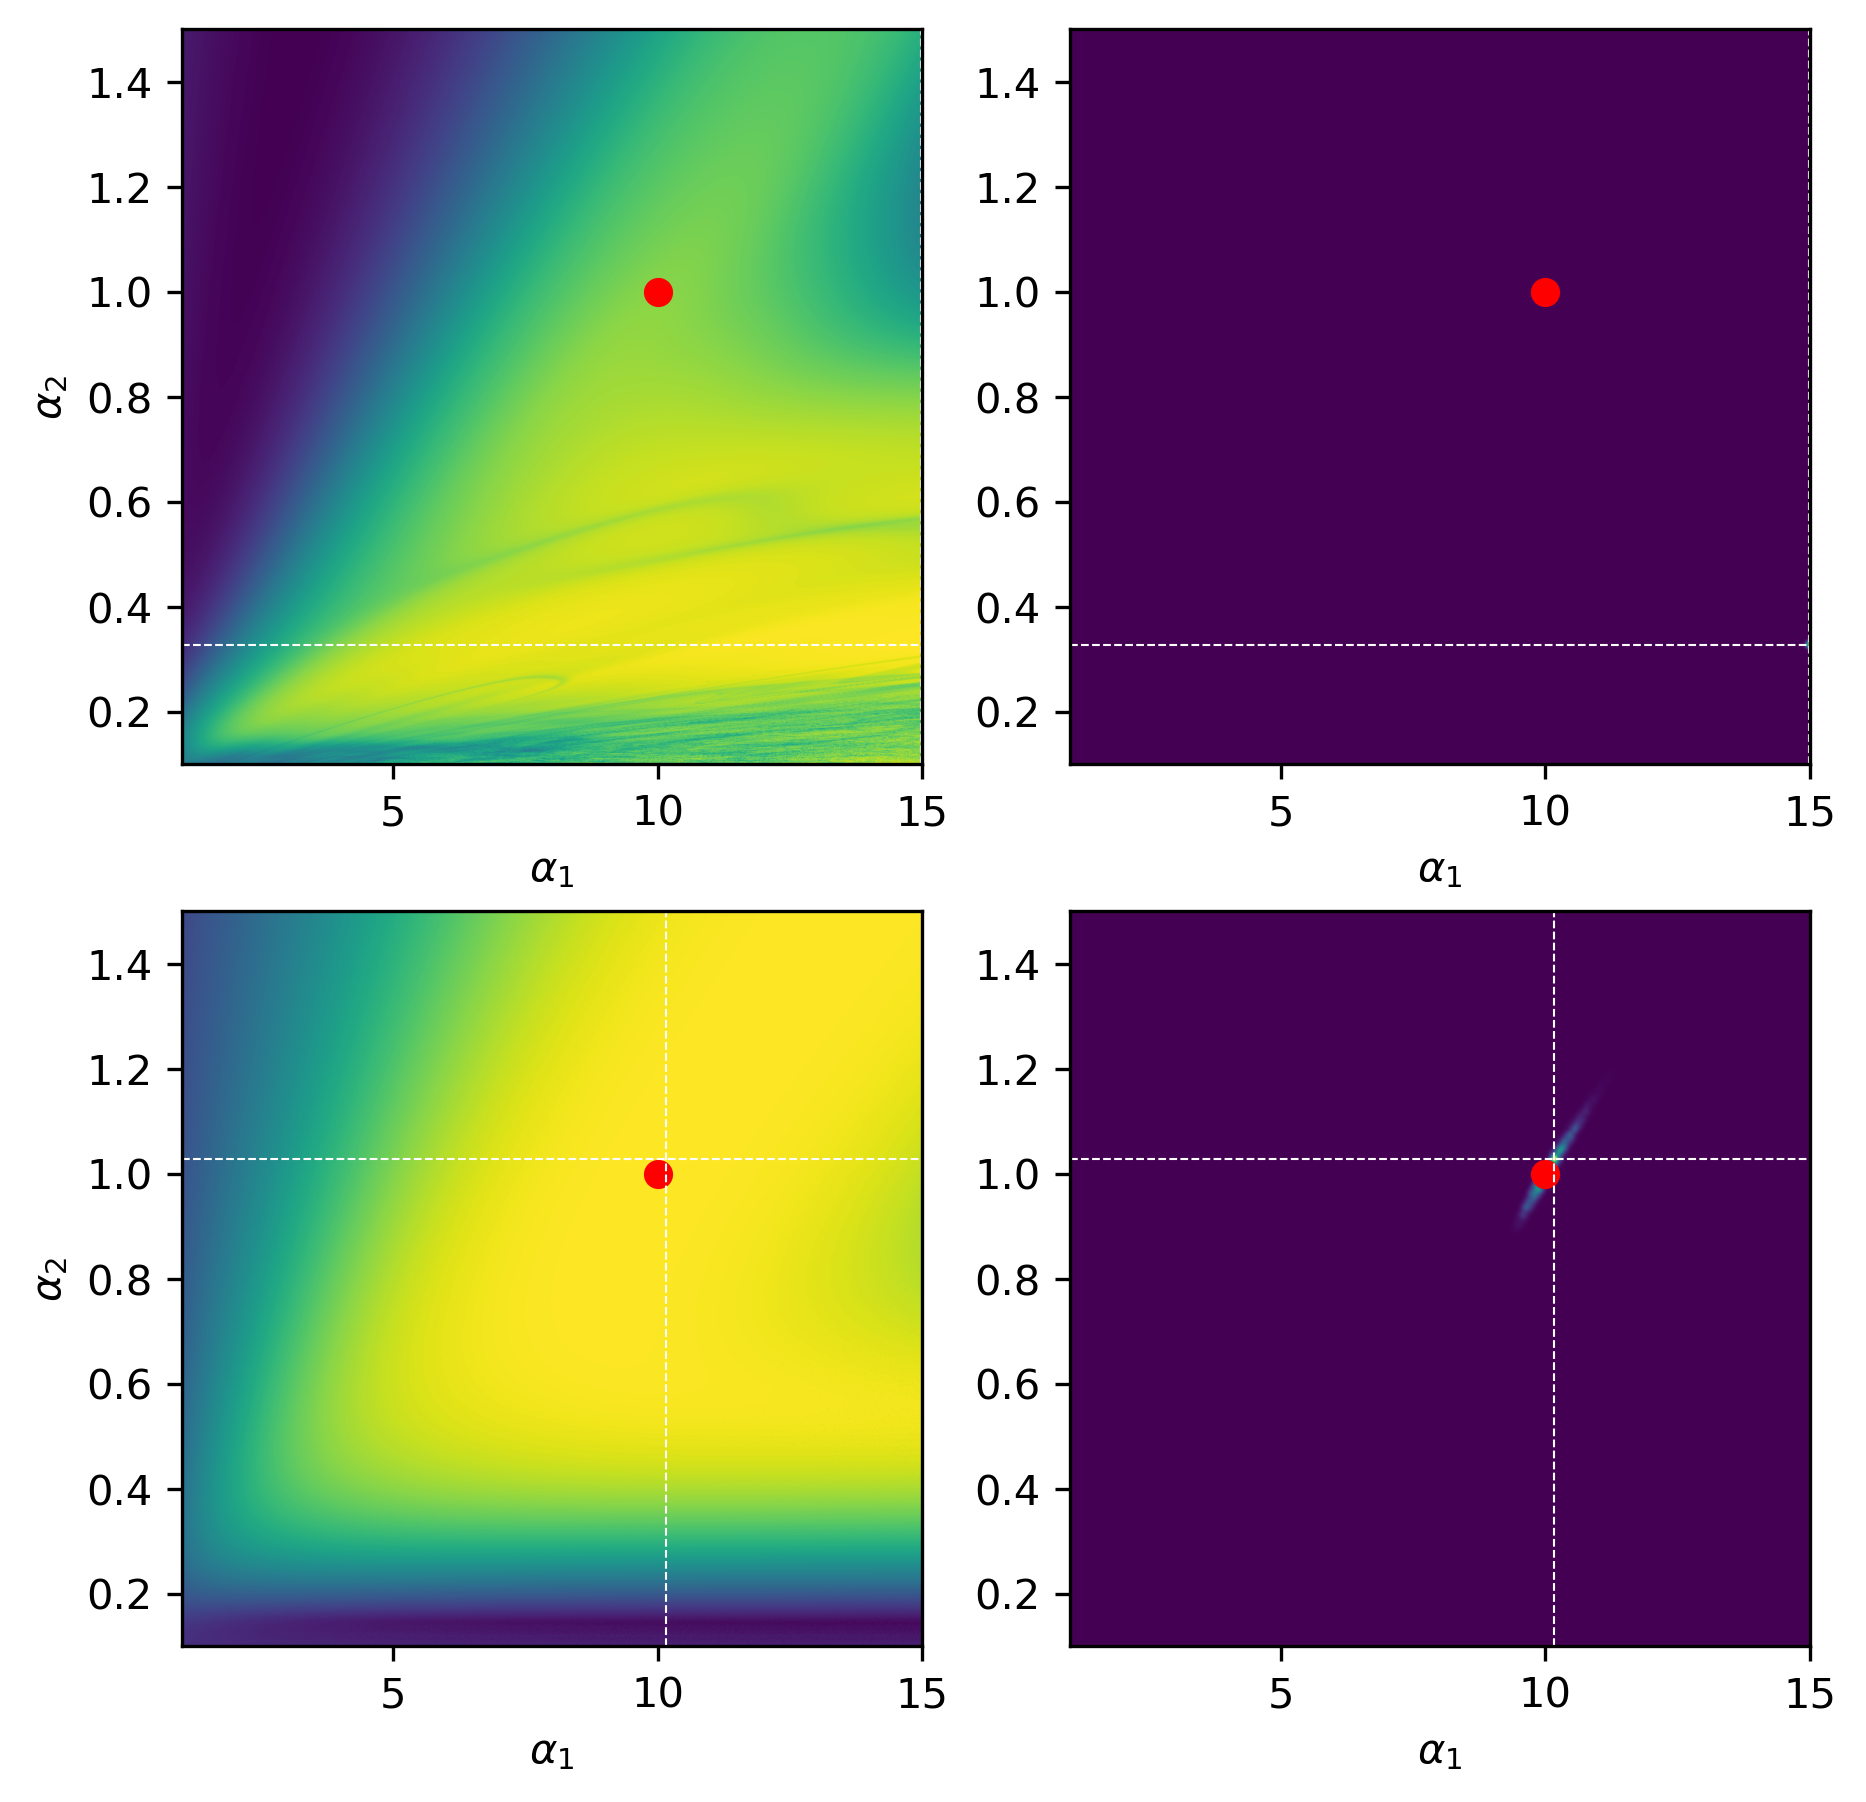

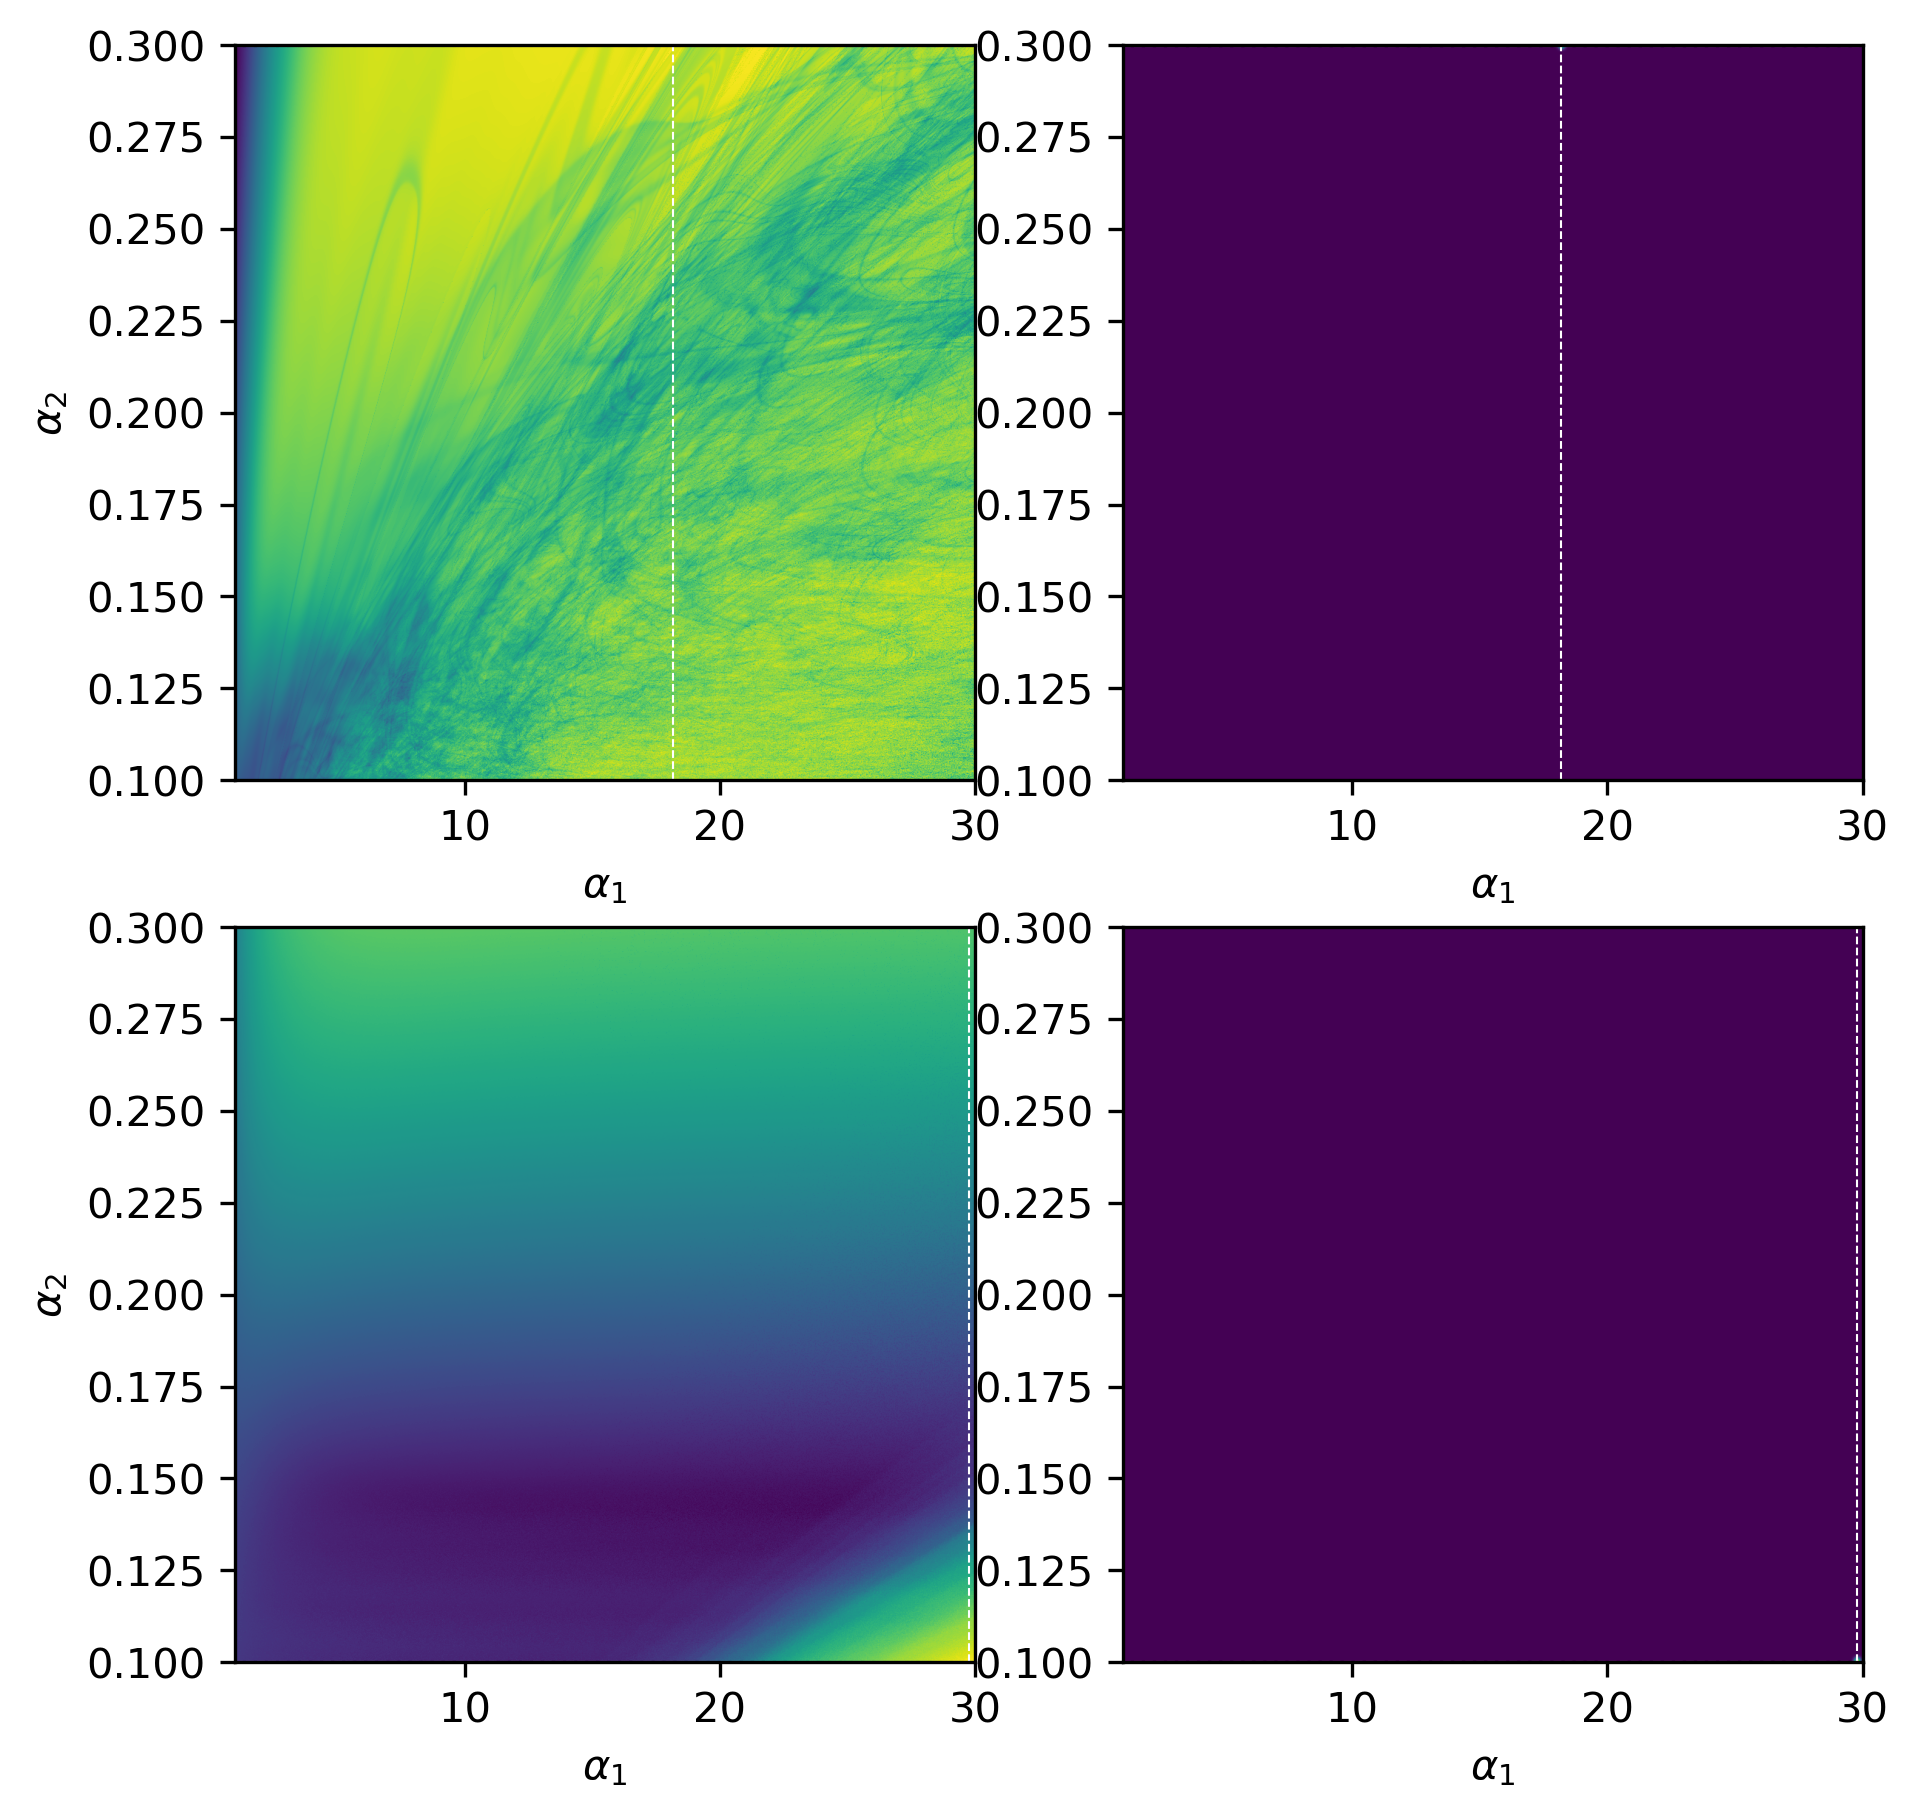

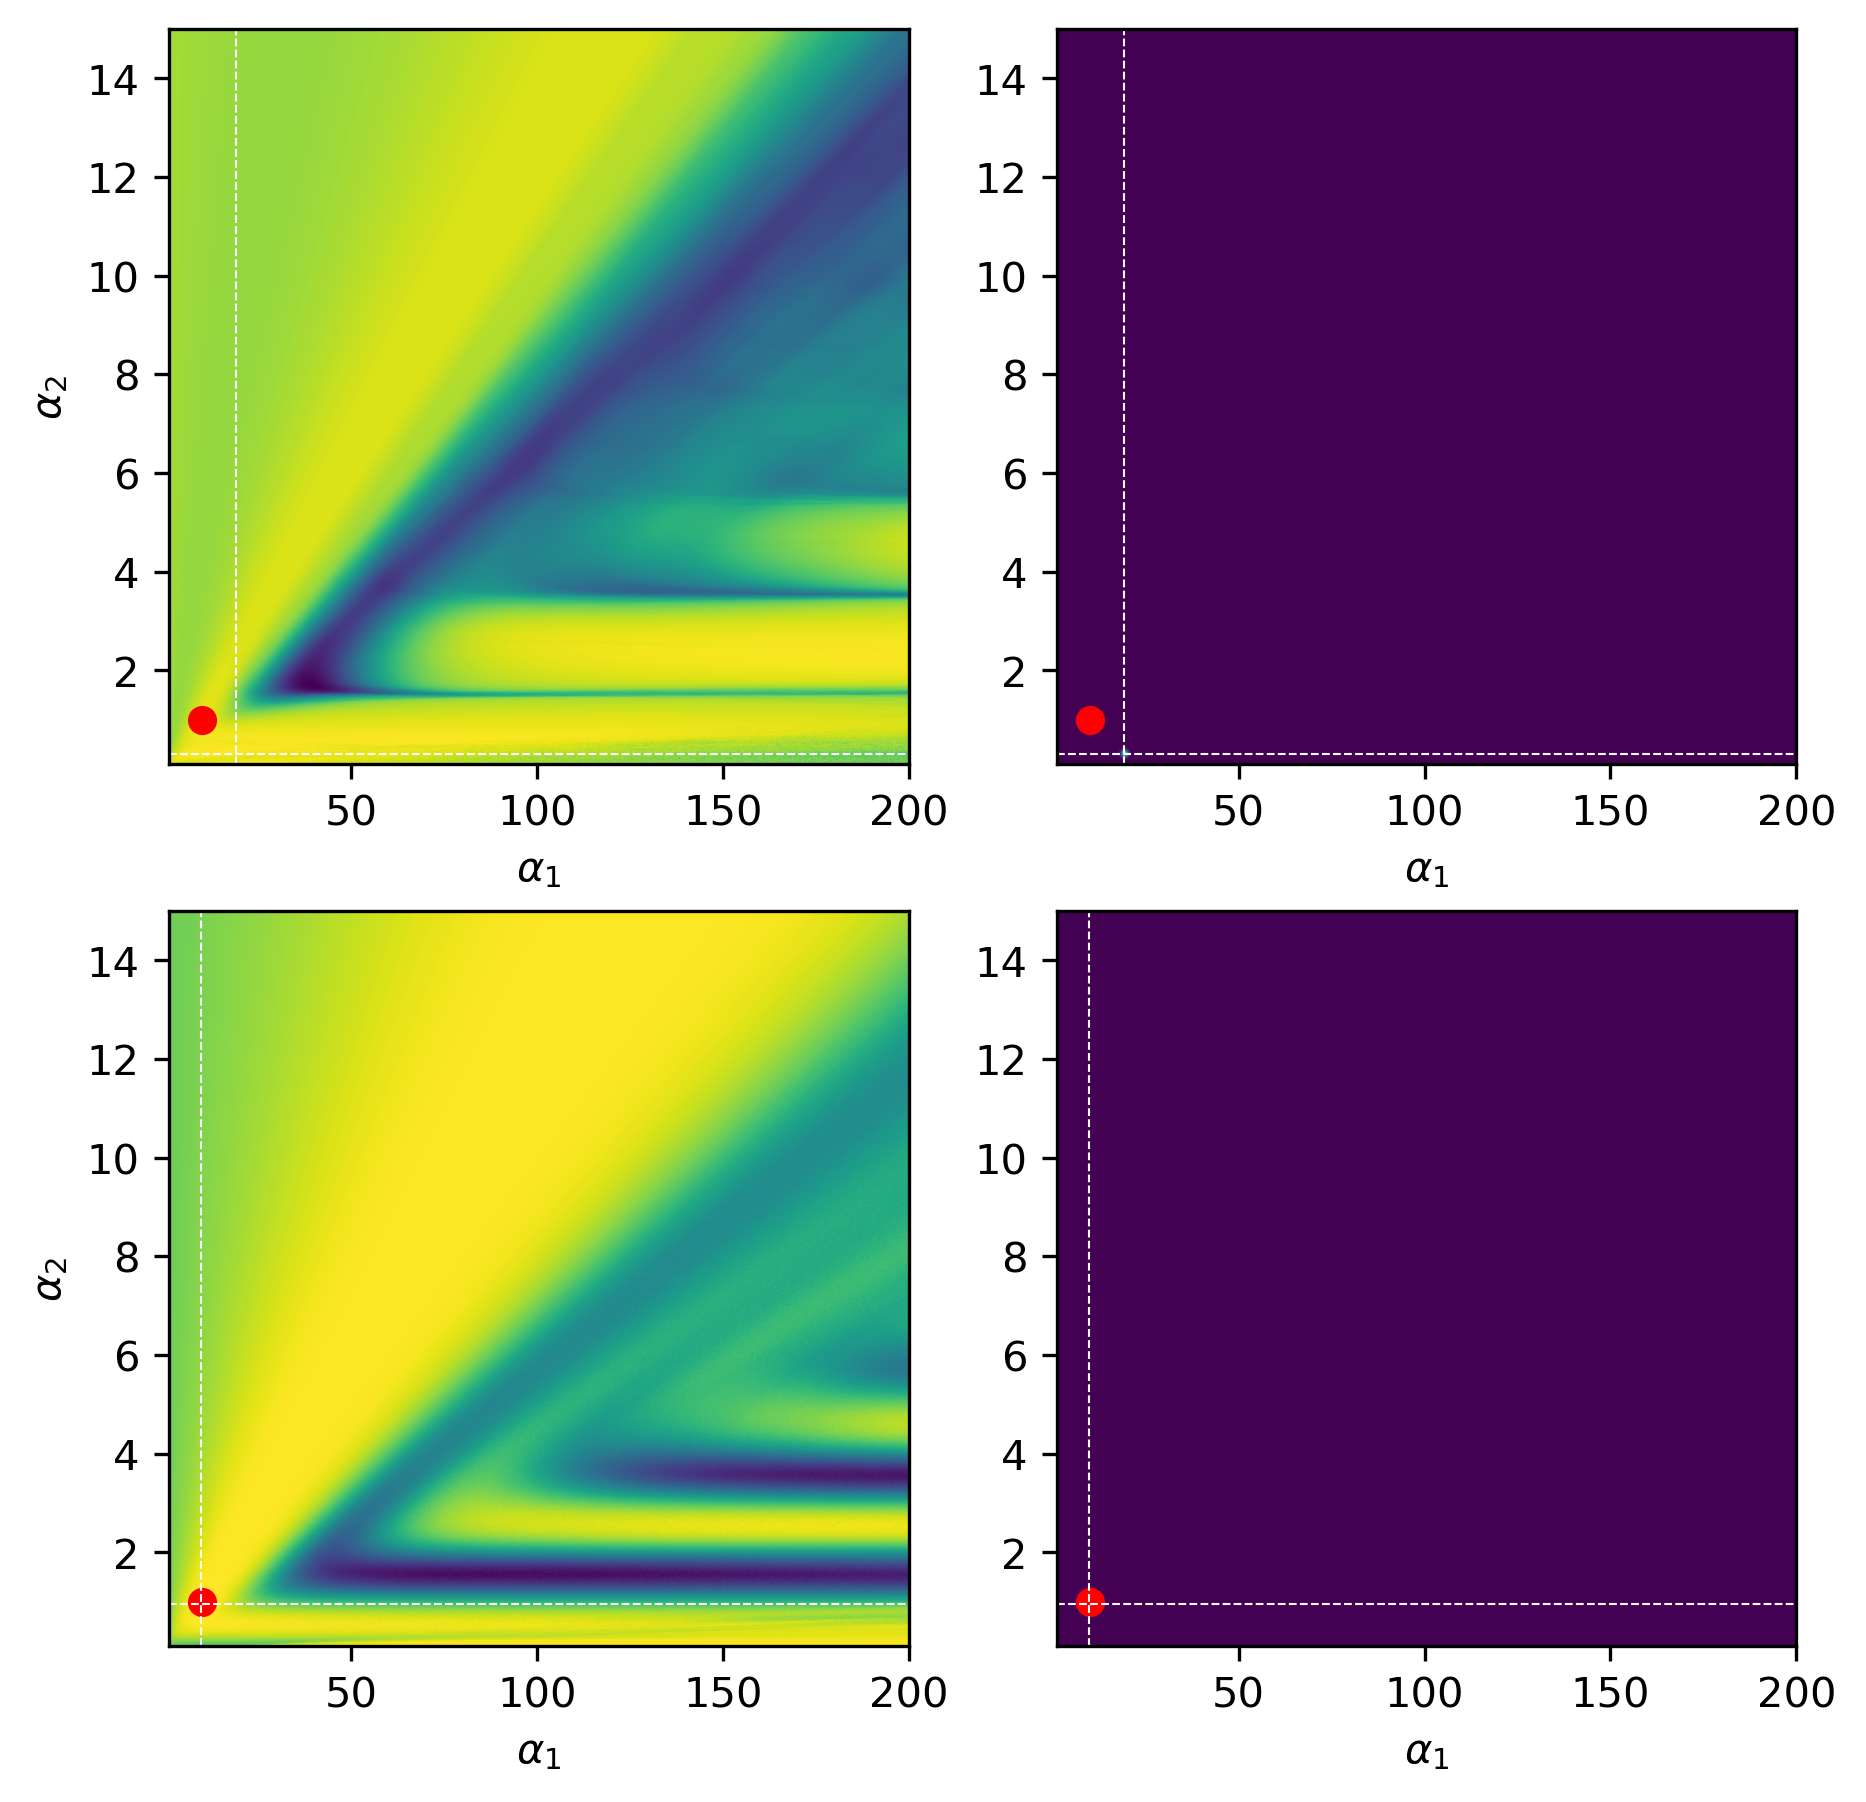

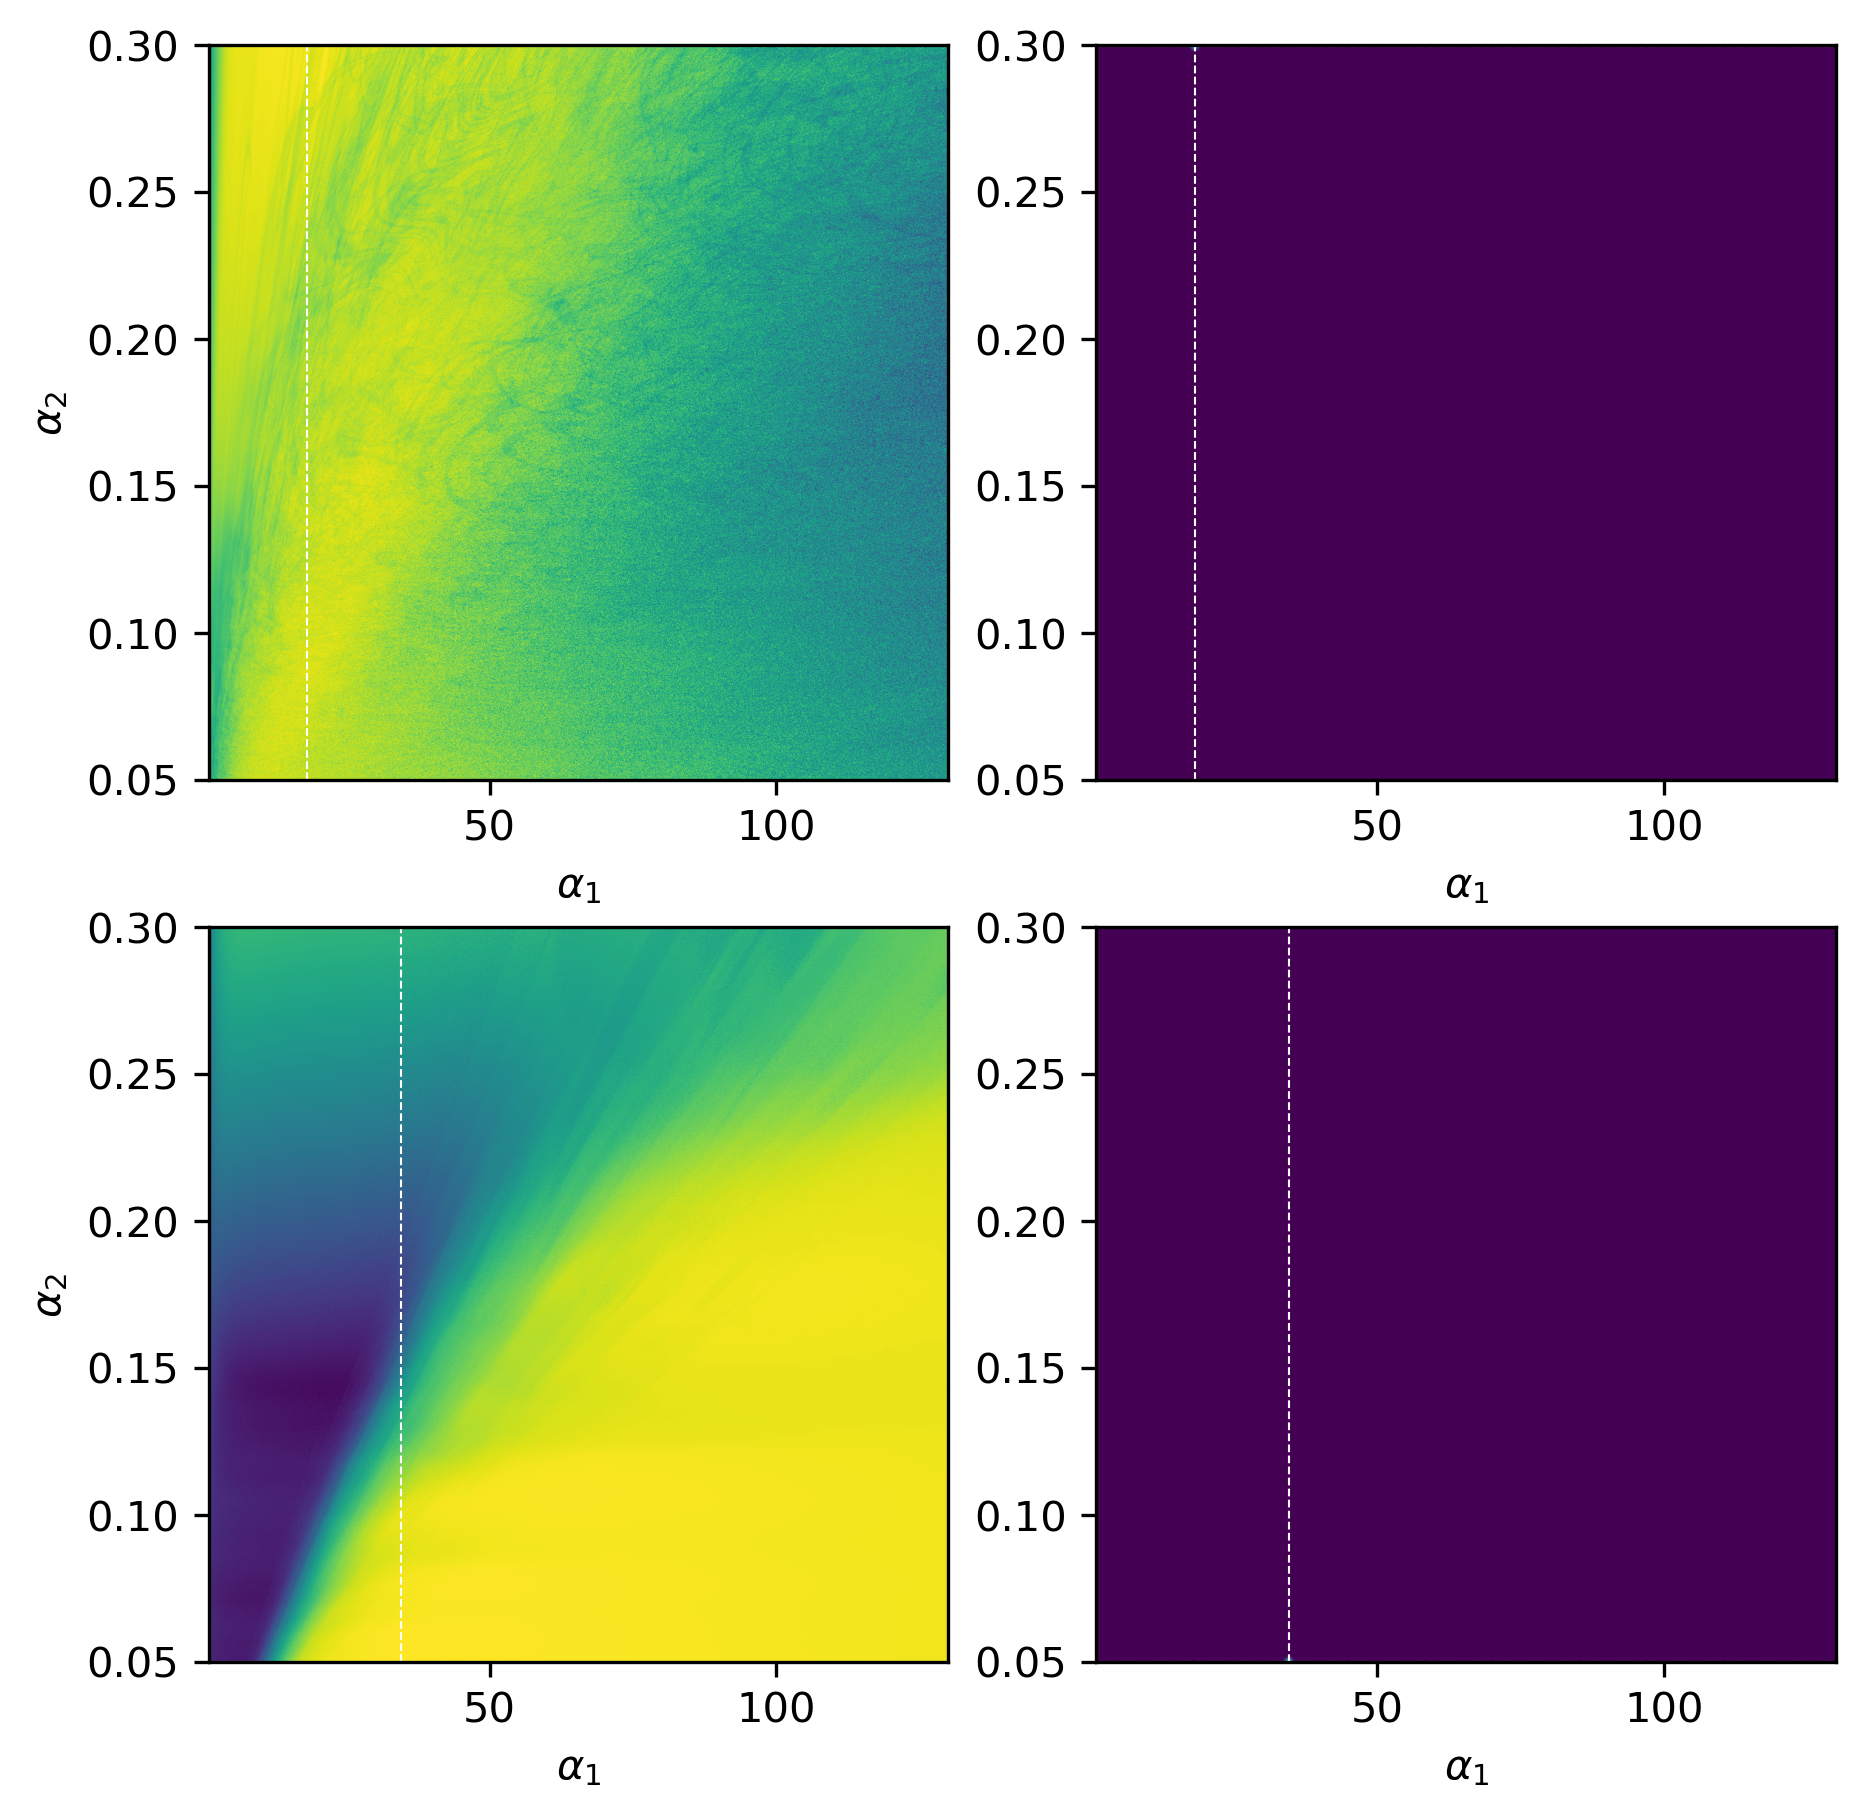

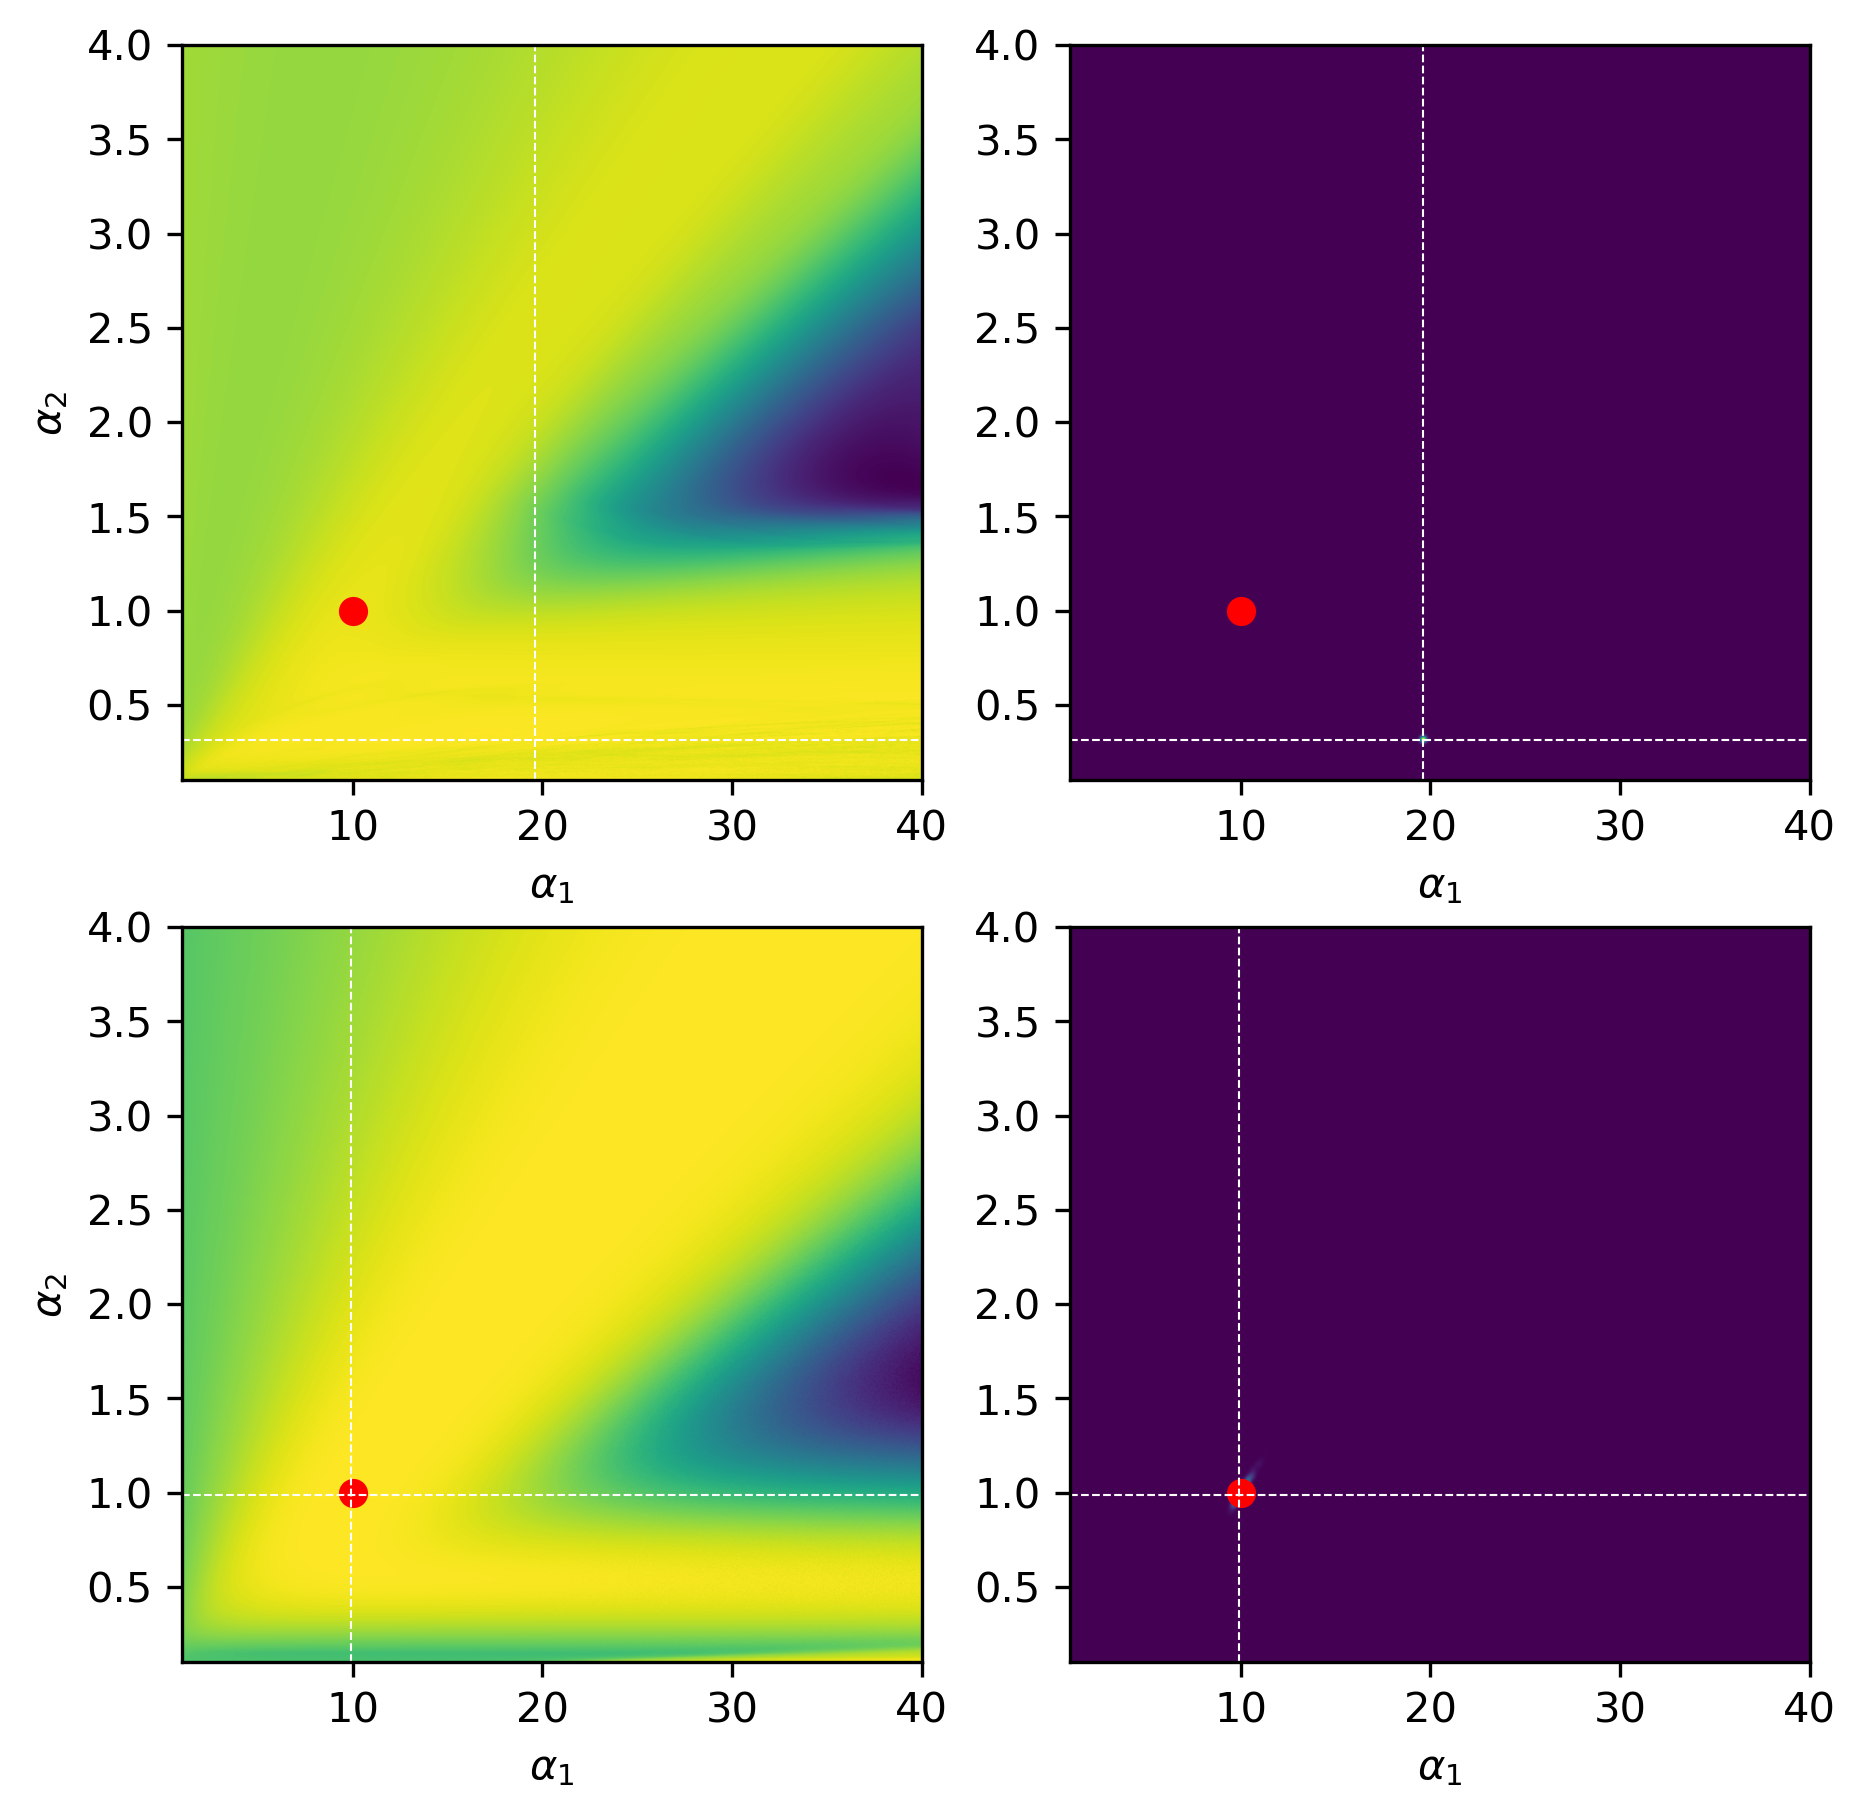

In [21]:
for i in range(1, 6):
    stitch_data(f'./view_{i}', delete_chunks=False)
    plot_dataset(f'./view_{i}', dpi=300, save_filename=f'./view_{i}.png')

In [ ]:
result_file = np.load('view_3/results.npz')
extent = result_file['extent']
LOGL_kf = result_file['LOGL_kf']
LOGL_pf = result_file['LOGL_pf']

In [ ]:
LOGL_pf.max() - LOGL_pf.min()